In [1]:
import scanpy as sc
import cafe

INFO                                                                                                                                                                                                    
             ██████╗ █████╗ ███████╗███████╗                                                                                                                                                            
           ██╔════╝██╔══██╗██╔════╝██╔════╝                                                                                                                                                             
           ██║     ███████║█████╗  █████╗                                                                                                                                                               
           ██║     ██╔══██║██╔══╝  ██╔══╝                                                                                                                                                           

## 模拟数据

In [2]:
adata = sc.read_h5ad("./output/26.10.14-time_strategy/dyngen_synthetic_dataset.h5ad")
adata

AnnData object with n_obs × n_vars = 500 × 2
    obs: 'time', 'time_raw', 'simulation_id', 'cell_type', 'split'
    var: 'transcription_rate', 'splicing_rate', 'mrna_decay_rate', 'translation_rate', 'protein_decay_rate', 'dyngen_id'
    uns: 'proposed_milestone_network', 'regulatory_network', 'simulation'
    obsm: 'X_emb'
    layers: 'Ms', 'Mu', 'protein', 'spliced', 'unspliced'

In [3]:
from scipy.sparse import csr_matrix

times = sorted(adata.obs["time"].unique())
tmaps = {}
for t1, t2 in zip(times[:-1], times[1:]):
    source = adata.obs.loc[adata.obs["time"] == t1, "simulation_id"].to_numpy()
    target = adata.obs.loc[adata.obs["time"] == t2, "simulation_id"].to_numpy()
    tmaps[t1, t2] = csr_matrix(source[:, None] == target[None, :], dtype=float)
[(pair, matrix.shape, matrix.nnz) for pair, matrix in tmaps.items()]


[((0.0, 0.5), (125, 125), 125),
 ((0.5, 1.0), (125, 125), 125),
 ((1.0, 1.5), (125, 125), 125)]

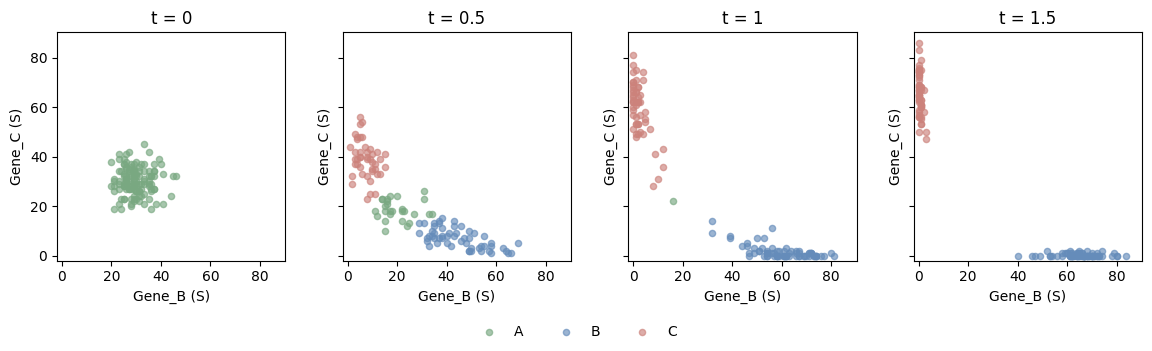

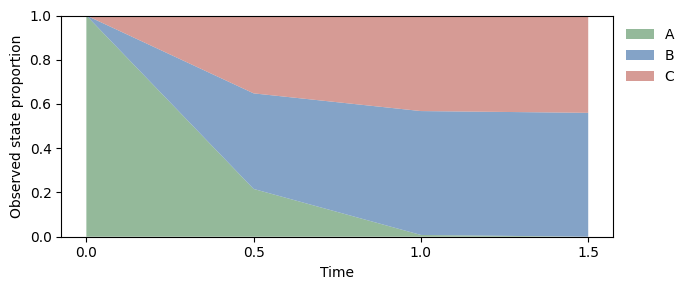

cell_type,A,B,C
time,,,
0.0,125,0,0
0.5,27,54,44
1.0,1,70,54
1.5,0,70,55


cell_type    A   B   C
time                  
0.0        125   0   0
0.5         27  54  44
1.0          1  70  54
1.5          0  70  55


In [4]:
import matplotlib.pyplot as plt
import pandas as pd

times = sorted(adata.obs["time"].unique())
palette = {"A": "#79a881", "B": "#658cba", "C": "#cc827b"}
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6), sharex=True, sharey=True)
limit = float(adata.X.max()) * 1.05
for ax, t in zip(axes, times):
    mask = adata.obs["time"] == t
    for label, color in palette.items():
        xy = adata.X[mask & (adata.obs["cell_type"] == label)]
        ax.scatter(xy[:, 0], xy[:, 1], s=20, alpha=.65, color=color, label=label)
    ax.set(xlabel="Gene_B (S)", ylabel="Gene_C (S)", title=f"t = {t:g}",
           xlim=(-2, limit), ylim=(-2, limit))
    ax.set_aspect("equal", adjustable="box")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, frameon=False)
fig.subplots_adjust(bottom=.24, wspace=.25)
plt.show()

counts = pd.crosstab(adata.obs["time"], adata.obs["cell_type"]).reindex(columns=list(palette), fill_value=0)
proportions = counts.div(counts.sum(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(7, 3))
ax.stackplot(times, proportions.T, labels=proportions.columns, colors=list(palette.values()), alpha=.8)
ax.set(xlabel="Time", ylabel="Observed state proportion", ylim=(0, 1), xticks=times)
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1, 1))
fig.tight_layout()
plt.show()
display(counts)
print(counts.to_string())


## Tmap Sankey

带宽为 simulation_id 匹配的原始支持量，节点为时间×状态。


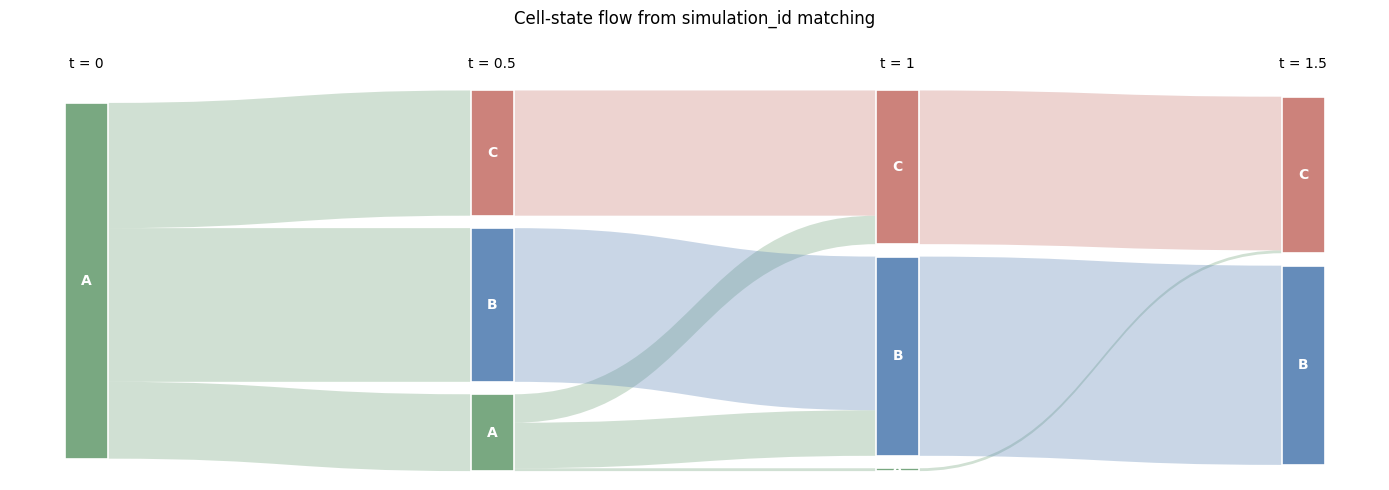

In [5]:

cafe.plot.plot_sankey(adata, tmaps, time_key="time", cluster_key="cell_type", palette=palette,
                      title="Cell-state flow from simulation_id matching",
                      save="./output/26.10.14-time_strategy/tmap_sankey.png")
plt.show()


## Base

同一 simulation_id 的相邻时点细胞作为已知匹配，用于验证转换，不是模型推断。Base 保留簇级最强去向与全局时间类别进度。


In [ ]:
fadata = cafe.data.FateAnnData.from_anndata(adata.copy())
fadata.uns["cell_type_colors"] = list(palette.values())
fadata.obs["time"] = pd.Categorical(fadata.obs["time"], categories=times, ordered=True)
fadata.add_prior_information(time_key="time", cluster="cell_type", basis="X_emb")
fadata.add_model_name("time_base")
fadata.add_trajectory_time(tmaps, strategy="base")
fadata.get_milestone_wrapper().milestone_network


,from,to,length,directed
0,A,B,2.18571,True
1,A,C,2.78181,True
2,B,B,1.00000,True
3,C,C,1.00000,True


## Timezone

Waterfall 两级聚合：源细胞行归一化 → 时间×类型 → 合并同类型。全局比例包含自环；展示默认隐藏自环。
细胞沿 tmap 追踪首次类型变化选择分支，进度按该边源类型最早、目标类型最晚观测时间线性归一化。


In [7]:
fadata.add_model_name("time_timezone")
fadata.add_trajectory_time(tmaps, strategy="timezone", flow_threshold=0, relative_threshold=0)
display(fadata.get_milestone_wrapper().milestone_network)
fadata.raw_wrapper_dict["global_edges"]


,from,to,length,directed
0,A,B,1.5,True
1,A,C,1.5,True


,source,target,support,n_windows,transition_fraction,n_source_cells,n_mapped_cells,is_self_loop,retained
0,A,A,28.0,2,0.183007,153,153,True,False
1,A,B,70.0,2,0.457516,153,153,False,True
2,A,C,55.0,3,0.359477,153,153,False,True
3,B,B,124.0,2,1.000000,124,124,True,False
4,C,C,98.0,2,1.000000,98,98,True,False


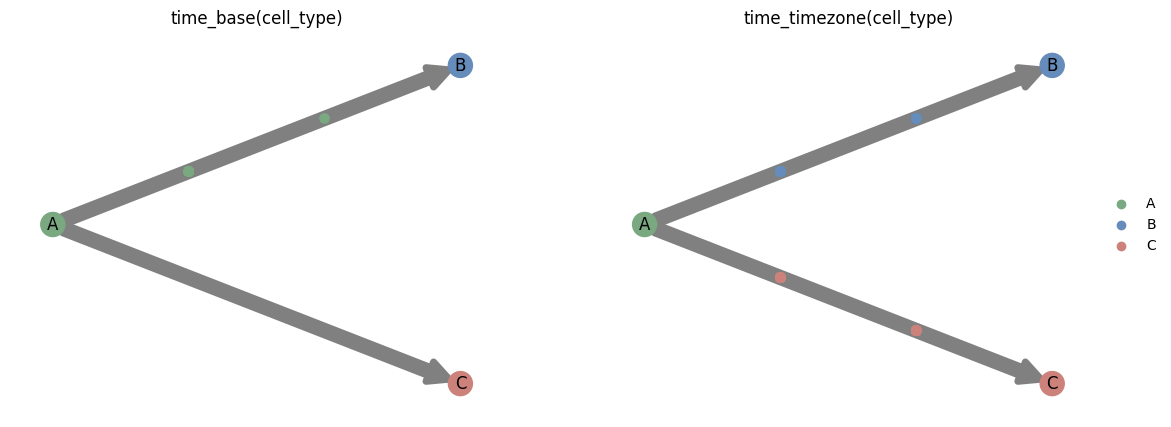

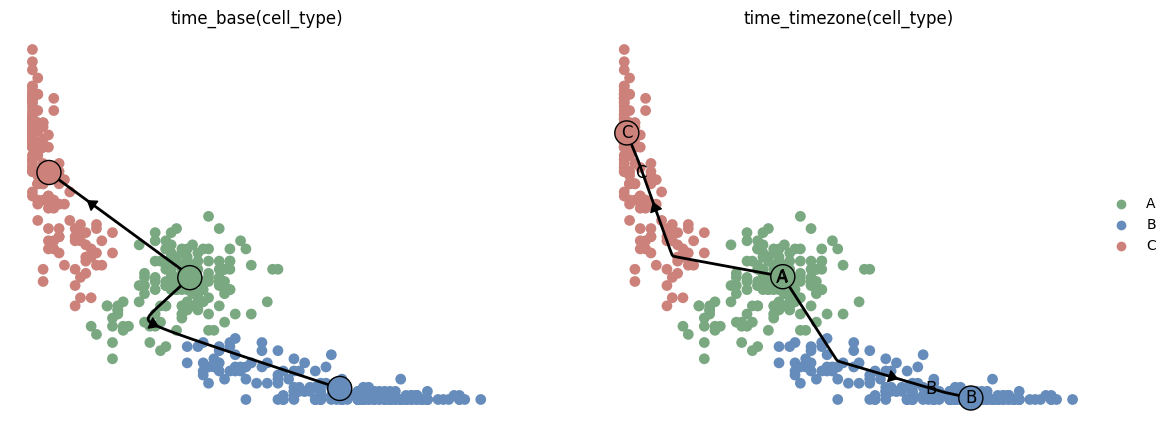

In [8]:
models = ["time_base", "time_timezone"]
cafe.plot.plot_graph(fadata, model_name=models, color="cell_type", layout_rankdir="LR", figsize=(14, 5))
plt.show()
cafe.plot.plot_trajectory(fadata, model_name=models, basis="X_emb", color="cell_type", show_milestone_labels=True, figsize=(14, 5))
plt.show()


In [9]:
pd.DataFrame({name: {
    "milestones": len(fadata.get_milestone_wrapper(name).id_list),
    "edges": len(fadata.get_milestone_wrapper(name).milestone_network),
    "cells": len(fadata.get_milestone_wrapper(name).cell_id_list),
    "progress_values": sorted(fadata.get_milestone_wrapper(name).progressions["percentage"].unique()),
} for name in models}).T


,milestones,edges,cells,progress_values
time_base,3,4,500,"[0.0, 0.3333333333333333, 0.6666666666666666, ..."
time_timezone,3,2,500,"[0.0, 0.3333333333333333, 0.6666666666666666, ..."


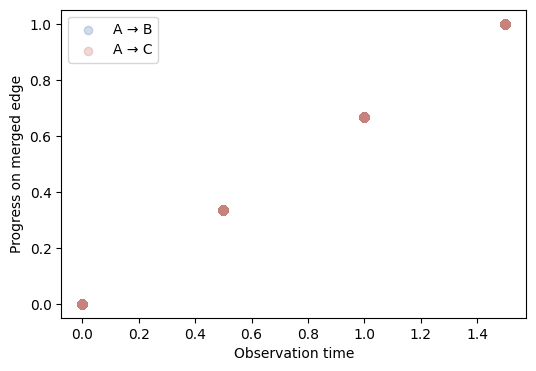

In [10]:
positions = fadata.get_raw_wrapper_dict("time_timezone")["cell_positions"].copy()
positions["time"] = fadata.obs.loc[positions["cell_id"], "time"].to_numpy(dtype=float)
fig, ax = plt.subplots(figsize=(6, 4))
for (source, target), cells in positions.query("status != 'unmatched'").groupby(["from", "to"]):
    ax.scatter(cells["time"], cells["percentage"], c=palette[target], alpha=0.3, label=f"{source} → {target}")
ax.set(xlabel="Observation time", ylabel="Progress on merged edge", ylim=(-0.05, 1.05))
ax.legend()
plt.show()


## Notes

- Base 使用全局簇流与簇级最强去向；Timezone 使用逐源细胞等权的两级聚合与细胞级时序路径。
- 同类型跨时间合并为一个里程碑；时间×类型中间表保留在 raw_wrapper_dict。
- progressions 是所选分化边的时间位置，不是命运概率或从表达推断的分化程度。无法匹配的细胞保留在类型节点上。
- 桑基图仍显示原始 tmap 权重；Timezone 的 support 是行归一化后的支持量。simulation_id 匹配是模拟数据的已知信息。
